In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df1 = pd.read_csv("AI_Human.csv")
df2AI = pd.read_csv("AI_Generated.csv")
df2Human = pd.read_csv("Human-Written.csv")
df = df1[:1000]
df2 = pd.concat([df2AI, df2Human], ignore_index=True)


# Check the column names first
print(df1.columns)
print(df1.shape)
print(df1.head())
print(df2.columns)
print(df2.head())


Fontconfig warning: ignoring UTF-8: not a valid region tag
Matplotlib is building the font cache; this may take a moment.


Index(['text', 'generated'], dtype='str')
(487235, 2)
                                                text  generated
0  Cars. Cars have been around since they became ...        0.0
1  Transportation is a large necessity in most co...        0.0
2  "America's love affair with it's vehicles seem...        0.0
3  How often do you ride in a car? Do you drive a...        0.0
4  Cars are a wonderful thing. They are perhaps o...        0.0
Index(['Model', 'Model_Version', 'Topic', 'Generated', 'Paraphrased',
       'Translated', 'Humanized', 'Text', 'Source', 'Type', 'Year', 'Authors'],
      dtype='str')
     Model Model_Version             Topic  \
0  ChatGPT   GPT-4-turbo       Mathematics   
1  ChatGPT   GPT-4-turbo           Biology   
2  ChatGPT   GPT-4-turbo           History   
3  ChatGPT   GPT-4-turbo         Economics   
4  ChatGPT   GPT-4-turbo  Computer Science   

                                           Generated  \
0  Calculus is a branch of mathematics that focus...   
1  C

In [10]:
# Looking at average sentence lengths
import re

def avg_sentence_length(text):
    # Split on . ! ? and drop empty pieces
    sentences = [s for s in re.split(r"[.!?]+", text) if s.strip()]
    if not sentences:
        return 0
    return sum(len(s.split()) for s in sentences) / len(sentences)

df["avg_sentence_len"] = df["text"].apply(avg_sentence_length)

sentence_result = df.groupby("generated")["avg_sentence_len"].mean()
sentence_result.index = ["Human", "AI"]
print(sentence_result)

Human    19.856098
AI       22.409091
Name: avg_sentence_len, dtype: float64


                       Human    AI
commas             24.267535   9.5
periods            29.185371  10.5
semicolons          0.000000   0.0
colons              0.528056   0.0
question marks      1.040080   0.0
exclamation marks   0.315631   0.5
quotes              7.815631   0.0
apostrophes         5.226453   1.5
                               Human        AI
commas_per_1000             7.460856  6.581121
periods_per_1000            9.228682  7.389381
semicolons_per_1000         0.000000  0.000000
colons_per_1000             0.154941  0.000000
question marks_per_1000     0.331264  0.000000
exclamation marks_per_1000  0.101654  0.333333
quotes_per_1000             2.386818  0.000000
apostrophes_per_1000        1.647137  1.070796


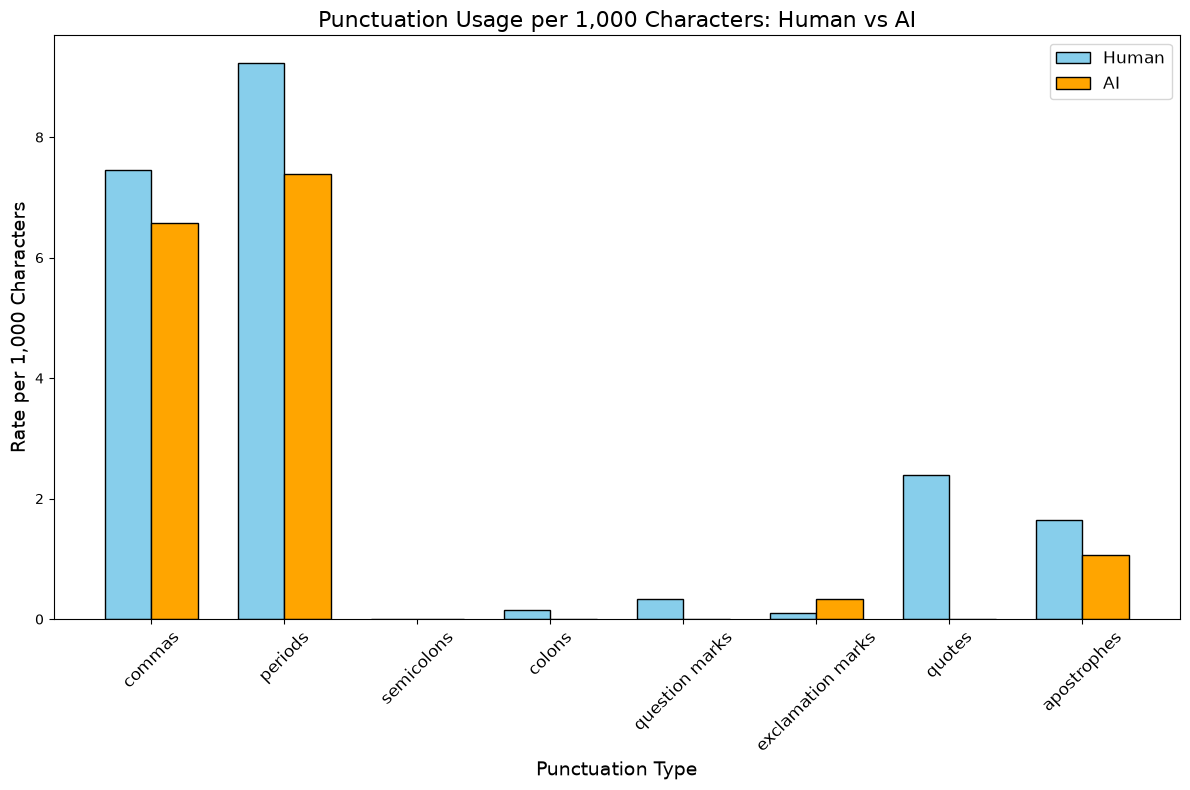

In [16]:
import matplotlib.pyplot as plt

# Define punctuation marks and their names
marks = {
    ",": "commas",
    ".": "periods",
    ";": "semicolons",
    ":": "colons",
    "?": "question marks",
    "!": "exclamation marks",
    '"': "quotes",
    "'": "apostrophes",
}

# Calculate counts and rates per 1,000 characters
for mark, name in marks.items():
    # Average count per essay
    df[name] = df["text"].apply(lambda t: t.count(mark))
    # Count per 1,000 characters, so longer essays don't skew the result
    df[name + "_per_1000"] = df[name] / df["text"].str.len() * 1000

# Average count per essay
counts = df.groupby("generated")[list(marks.values())].mean()
counts.index = ["Human", "AI"]
print(counts.T)

# Per 1,000 characters (fairer comparison)
rates = df.groupby("generated")[[n + "_per_1000" for n in marks.values()]].mean()
rates.index = ["Human", "AI"]
print(rates.T)

# Plotting the rates for all punctuation types
plt.figure(figsize=(12, 8))

# Create a grouped bar chart
x = range(len(marks))  # Number of punctuation types
width = 0.35  # Width of the bars

# Bar positions for Human and AI
human_bars = [rates.loc["Human", n + "_per_1000"] for n in marks.values()]
ai_bars = [rates.loc["AI", n + "_per_1000"] for n in marks.values()]

# Plot bars
plt.bar(x, human_bars, width, label="Human", color="skyblue", edgecolor="black")
plt.bar([p + width for p in x], ai_bars, width, label="AI", color="orange", edgecolor="black")

# Add labels and title
plt.xticks([p + width / 2 for p in x], list(marks.values()), rotation=45, fontsize=12)
plt.title("Punctuation Usage per 1,000 Characters: Human vs AI", fontsize=16)
plt.xlabel("Punctuation Type", fontsize=14)
plt.ylabel("Rate per 1,000 Characters", fontsize=14)
plt.legend(fontsize=12)
plt.tight_layout()

# Show the plot
plt.show()

[nltk_data] Downloading package punkt to /Users/mayahkg/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /Users/mayahkg/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.


           nouns_per_100_words  adjectives_per_100_words  verbs_per_100_words
generated                                                                    
Human                24.571289                  7.414222            16.274298
AI                   30.310715                 13.375815            13.179453


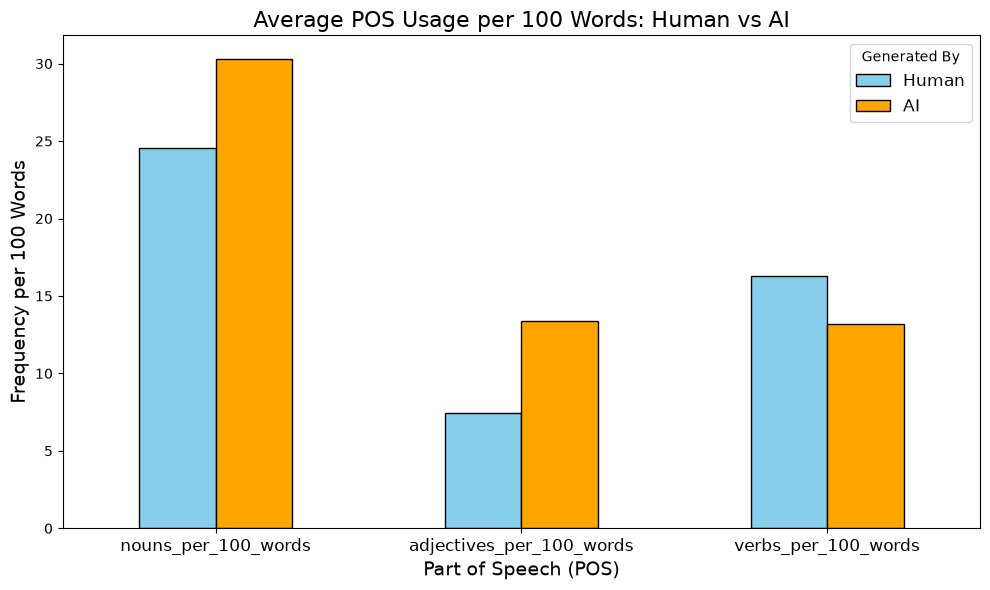

In [17]:
import pandas as pd
import nltk
from collections import Counter
import ssl
import matplotlib.pyplot as plt

# Work around the macOS python.org SSL certificate problem
try:
    _create_unverified_https_context = ssl._create_unverified_context
except AttributeError:
    pass
else:
    ssl._create_default_https_context = _create_unverified_https_context

# Download necessary NLTK resources
nltk.download("punkt")
nltk.download("averaged_perceptron_tagger")

# Rebuild the 100-per-group sample
df = pd.read_csv("AI_Human.csv")
small = df.groupby("generated").head(100).copy()

# Function to calculate noun, adjective, and verb statistics
def pos_stats(text):
    words = nltk.word_tokenize(text)
    tags = nltk.pos_tag(words)
    nouns = [w.lower() for w, tag in tags if tag.startswith("NN")]
    adjectives = [w.lower() for w, tag in tags if tag.startswith("JJ")]
    verbs = [w.lower() for w, tag in tags if tag.startswith("VB")]
    return pd.Series({
        "noun_count": len(nouns),
        "nouns_per_100_words": len(nouns) / max(len(words), 1) * 100,
        "adjective_count": len(adjectives),
        "adjectives_per_100_words": len(adjectives) / max(len(words), 1) * 100,
        "verb_count": len(verbs),
        "verbs_per_100_words": len(verbs) / max(len(words), 1) * 100
    })

# Apply the function to the text column
small = small.join(small["text"].apply(pos_stats))

# Group by "generated" and calculate the mean for each POS metric
pos_result = small.groupby("generated")[[
    "nouns_per_100_words", "adjectives_per_100_words", "verbs_per_100_words"
]].mean()

# Rename the index for clarity
pos_result = pos_result.rename(index={0: "Human", 1: "AI"})
print(pos_result)

# Plot the results in a bar chart
pos_result.T.plot(kind="bar", figsize=(10, 6), color=["skyblue", "orange"], edgecolor="black")
plt.title("Average POS Usage per 100 Words: Human vs AI", fontsize=16)
plt.ylabel("Frequency per 100 Words", fontsize=14)
plt.xlabel("Part of Speech (POS)", fontsize=14)
plt.xticks(rotation=0, fontsize=12)
plt.legend(title="Generated By", fontsize=12)
plt.tight_layout()
plt.show()

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 18283.37it/s]


           avg_surprisal  std_surprisal
generated                              
Human           3.477276       2.934448
AI              2.857872       2.606304


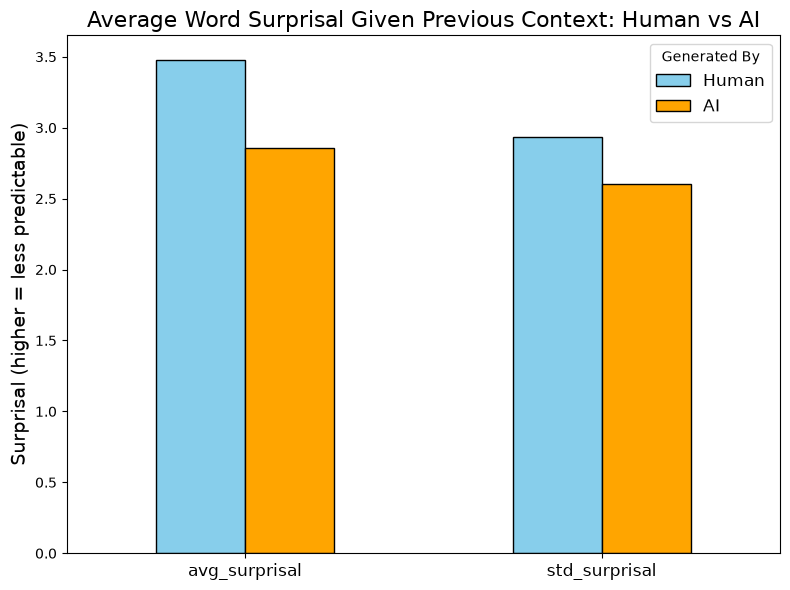

In [4]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
from transformers import GPT2LMHeadModel, GPT2TokenizerFast

tok = GPT2TokenizerFast.from_pretrained("gpt2")
model = GPT2LMHeadModel.from_pretrained("gpt2").eval()

# Build the sample here: 50 essays per group (raise this for more)
df = pd.read_csv("AI_Human.csv")
sample = df.groupby("generated").head(50).copy()

def surprisal_stats(text, max_tokens=256):
    ids = tok(text, return_tensors="pt", truncation=True, max_length=max_tokens)["input_ids"]
    with torch.no_grad():
        logits = model(ids).logits
    logprobs = torch.log_softmax(logits[0, :-1], dim=-1)  # predictions for tokens 2..n
    target = ids[0, 1:]
    surprisal = -logprobs[torch.arange(len(target)), target]
    return pd.Series({
        "avg_surprisal": surprisal.mean().item(),
        "std_surprisal": surprisal.std().item(),
    })

sample = sample.join(sample["text"].apply(surprisal_stats))

surprisal_result = sample.groupby("generated")[["avg_surprisal", "std_surprisal"]].mean()
surprisal_result = surprisal_result.rename(index={0: "Human", 1: "AI"})
print(surprisal_result)

surprisal_result.T.plot(kind="bar", figsize=(8, 6), color=["skyblue", "orange"], edgecolor="black")
plt.title("Average Word Surprisal Given Previous Context: Human vs AI", fontsize=16)
plt.ylabel("Surprisal (higher = less predictable)", fontsize=14)
plt.xlabel("")
plt.xticks(rotation=0, fontsize=12)
plt.legend(title="Generated By", fontsize=12)
plt.tight_layout()
plt.show()